In [1]:
%load_ext autoreload
%autoreload 2
import os
os.chdir('/nfs/home/dannis/AC-model/TIM')
import numpy as np
import matplotlib.pyplot as plt
from optimization import *
from tqdm import tqdm
import pandas as pd

import seaborn as sns

In [2]:
def get_str_inbetween(s, start, end):
    return (s.split(start))[1].split(end)[0]

def get_mip_info(base_dir):
    # Storage for all trade data
    # Initialize list to store data
    data_rows = []

    # Iterate through subfolders
    for subfolder in tqdm(os.listdir(base_dir)):
        subfolder_path = os.path.join(base_dir, subfolder)
        if os.path.isdir(subfolder_path):            
            # Iterate through files in subfolder
            nTrades = int(get_str_inbetween(subfolder, 'nTrades', '_'))
            nScenarios = int(get_str_inbetween(subfolder, 'nScenarios', '_'))
            lossThresh = float(get_str_inbetween(subfolder, 'lossThresh', '_'))
            chanceThresh = float(get_str_inbetween(subfolder, 'chanceThresh', '_')) / 100
            M = int(get_str_inbetween(subfolder, 'M', '_'))
            scale = int(get_str_inbetween(subfolder, 'scale', '_'))
            sigma = float(get_str_inbetween(subfolder, 'sigma', '_')) if 'sigma' in subfolder else np.nan

            row = {
                'nTrades': nTrades,
                'nScenarios': nScenarios,
                'lossThresh': lossThresh,
                'chanceThresh': chanceThresh,
                'M': M,
                'scale': scale,
                'sigma': sigma
            }
            for filename in os.listdir(subfolder_path):
                if filename.endswith('.pkl'):
                    file_path = os.path.join(subfolder_path, filename)
                    # print(f"  Reading file: {filename}")
                    
                    with open(file_path, 'rb') as f:
                        data = pickle.load(f)
                    
                    trades = np.array(data['trades'])
                    seed = int(filename.split('_')[-1].split('.')[0])
                    
                    # Extract key info from filename and subfolder
                    row.update({
                        'subfolder': subfolder,
                        'filename': filename,
                        'status': data.get('status', 'unknown'),
                        'chance_slack': data.get('chance_slack', np.nan),
                        'obj_val': data.get('obj_val', np.nan),
                        'runtime': data.get('runtime', np.nan),
                        'seed': seed,
                    })
                    
                    for j, trade in enumerate(trades):
                        row[f'trade_{j}'] = trade

                    data_rows.append(row.copy())

    # Create DataFrame
    df = pd.DataFrame(data_rows)
    
    return df

### Vary mean

In [3]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_mean_4.8e-5',
             '/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_mean_4.9e-5',
             '/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_mean_5e-5',
             '/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_mean_5.05e-5',
             '/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_mean_5.1e-5']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    mean = float(base_dir.split('vary_mean_')[-1])
    df = get_mip_info(base_dir)
    df['gamma_mean'] = mean
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 2/2 [00:00<00:00, 939.48it/s]


In [4]:
combined_df.groupby(['nTrades', 'gamma_mean']).agg({
    'obj_val': ['mean', 'std'], 
    'chance_slack': ['mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val              chance_slack            \
                             mean          std         mean       std   
nTrades gamma_mean                                                      
150     0.000048    352808.194307   461.454999     0.500000  0.110995   
        0.000049    360177.294931   461.588063     0.273333  0.147874   
        0.000050    367740.827071   411.012901     0.030000  0.027568   
        0.000051    371933.291986   656.343673     0.000000  0.000000   
        0.000051    377080.619598  1223.753944     0.006667  0.010328   

                         status        
                   optimal rate count  
nTrades gamma_mean                     
150     0.000048            1.0     6  
        0.000049            1.0     6  
        0.000050            1.0     6  
        0.000051            1.0     6  
        0.000051            1.0     6

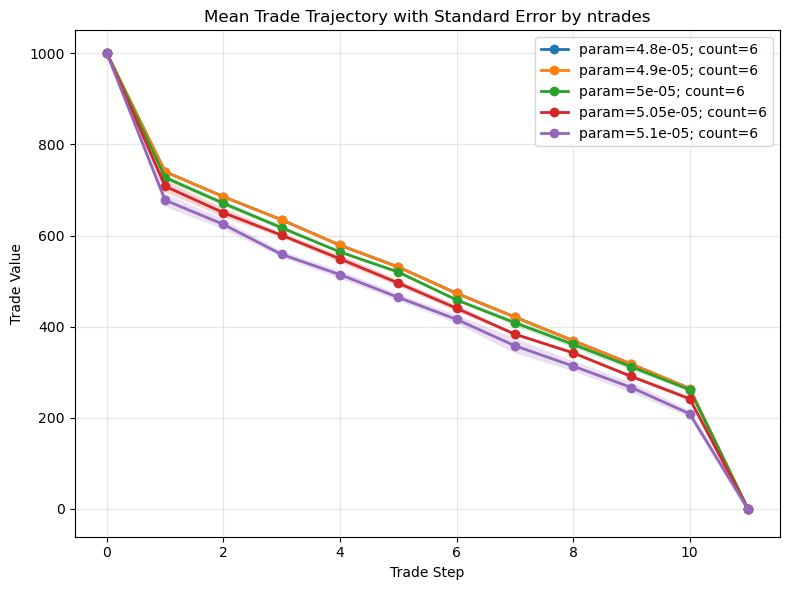

In [5]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['nScenarios'] == 1000) &
                         (combined_df['status'] == 2)]
df_success[trade_cols].multiply(df_success['scale'], axis=0)
plt.figure(figsize=(8, 6))

for gamma_mean, group_data in df_success.groupby('gamma_mean'):
  # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    plt.plot(x, y, marker='o', label=f'param={gamma_mean}; count={len(group_data)}', linewidth=2)

    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Trade Value')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Vary chance thresh

In [38]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_chance_thresh_sample_rho_5e-5']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 13/13 [00:00<00:00, 460.39it/s]


In [39]:
combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'obj_val': ['mean', 'std'], 
    'chance_slack': ['mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val               chance_slack            \
                               mean          std          mean       std   
nTrades chanceThresh                                                       
150     0.01                    NaN          NaN           NaN       NaN   
        0.02          385299.437506    72.608208  1.776357e-16  0.000000   
        0.03          378433.784078  2496.529010  5.555556e-03  0.013608   
        0.04          374292.643803   545.165986  8.333333e-03  0.012910   
        0.05          372828.024027   646.508118  3.333333e-03  0.008165   
        0.10          372293.111677   487.243352  3.650000e-01  0.073417   
400     0.01                    NaN          NaN           NaN       NaN   
        0.02          375576.086989  3237.278250  1.776357e-16  0.000000   
        0.03          372950.272850  3726.499510  0.000000e+00  0.000000   
        0.04          370633.377435  1608.370185  7.500000e-03  0.023717   
        0.05          369002.389684   486.853174  4.666667e-02  0.062823   
        0.10          369614.307938   977.256277  4.480000e-01  0.076565   

                           status        
                     optimal rate count  
nTrades chanceThresh                     
150     0.01             0.000000     6  
        0.02             0.500000     6  
        0.03             1.000000     6  
        0.04             0.833333     6  
        0.05             1.000000     6  
        0.10             1.000000     6  
400     0.01             0.000000     6  
        0.02             0.700000    10  
        0.03             0.900000    10  
        0.04             1.000000    10  
        0.05             1.000000     6  
        0.10             1.000000    10

Text(0.5, 1.0, 'Average Objective Value (Optimal Solutions Only)')

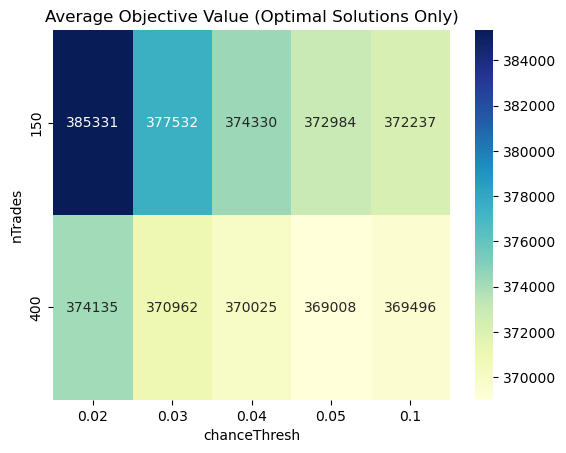

In [40]:
sns.heatmap(combined_df[(combined_df['nScenarios'] == 1000) & (combined_df['status'] == 2)].groupby(['nTrades', 'chanceThresh'])['obj_val'].median().unstack(),
            annot=True, fmt=".0f", cmap="YlGnBu")
plt.title('Average Objective Value (Optimal Solutions Only)')

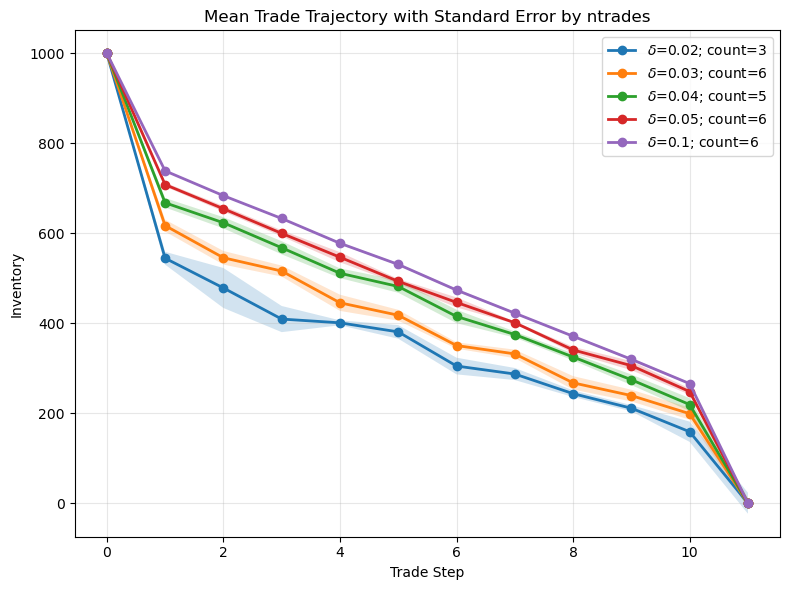

In [41]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['nScenarios'] == 1000) &
                         (combined_df['status'] == 2) &
                         (combined_df['nTrades'] == 150)]
df_success[trade_cols].multiply(df_success['scale'], axis=0)

plt.figure(figsize=(8, 6))


for gamma_mean, group_data in df_success.groupby('chanceThresh'):

    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    plt.plot(x, y, marker='o', label=f'$\delta$={gamma_mean}; count={len(group_data)}', linewidth=2)
    
    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Inventory')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## 1e-5

In [15]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250924_recenter_posteriors_1e-5']

# Combine data from multiple directories0250921_recenter_posteriors_5e-5
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 17/17 [00:00<00:00, 282.10it/s]


In [31]:
combined_df['failure_rate'] = (1-combined_df['chance_slack']) * combined_df['chanceThresh'] 
combined_df[combined_df['lossThresh'] == 100000].groupby(['nTrades', 'lossThresh', 'chanceThresh']).agg({
    'obj_val': ['mean', 'std', lambda x: np.quantile(x, 0.95)], 
    'failure_rate': ['mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val                             \
                                         mean          std    <lambda_0>   
nTrades lossThresh chanceThresh                                            
150     100000.0   0.05          77423.604340  1542.390001  79349.615155   
                   0.10          73923.972726   938.192331  75481.268135   
250     100000.0   0.05          77423.604340  1542.390001  79349.615155   
                   0.10          73923.972726   938.192331  75481.268135   
400     100000.0   0.05          77423.604340  1542.390001  79349.615155   
                   0.10          73923.972726   938.192331  75481.268135   
800     100000.0   0.05          77423.604340  1542.390001  79349.615155   
                   0.10          73923.972726   938.192331  75481.268135   

                                failure_rate                 status        
                                        mean       std optimal rate count  
nTrades lossThresh chanceThresh                                            
150     100000.0   0.05               0.0500  0.000000          1.0    10  
                   0.10               0.0996  0.000699          1.0    10  
250     100000.0   0.05               0.0500  0.000000          1.0    10  
                   0.10               0.0996  0.000699          1.0    10  
400     100000.0   0.05               0.0500  0.000000          1.0    10  
                   0.10               0.0996  0.000699          1.0    10  
800     100000.0   0.05               0.0500  0.000000          1.0    10  
                   0.10               0.0996  0.000699          1.0    10

/tmp/ipykernel_1267386/696609321.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


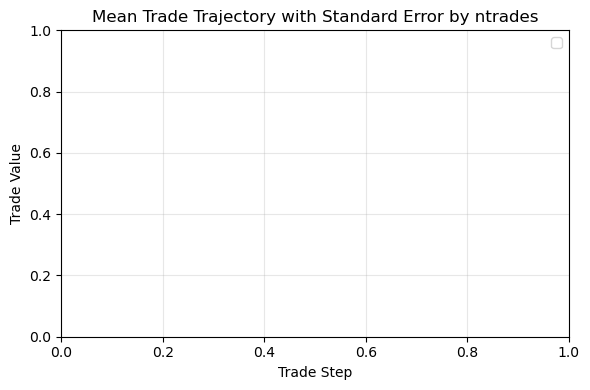

In [ ]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['chanceTresh'] == 1000) &
                         (combined_df['status'] == 2) &
                         (combined_df['scale'] == 100)]
ntrades_groups = df_success.groupby('nTrades')

plt.figure(figsize=(6, 4))

for nTrades, group_data in df_success.groupby('sigma'):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.cumsum(means)
    # Plot mean trajectory
    plt.plot(x, y, marker='o', label=f'nTrades={nTrades}; count={len(group_data)}', linewidth=2)

    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Trade Value')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## 5e-5

In [3]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250922_recenter_posteriors_5e-5']

# Combine data from multiple directories0250921_recenter_posteriors_5e-5
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

  0%|          | 0/36 [00:00<?, ?it/s]

100%|██████████| 36/36 [00:00<00:00, 451.61it/s]


In [4]:
combined_df['failure_rate'] = (1-combined_df['chance_slack']) * combined_df['chanceThresh'] 
combined_df[combined_df['scale'] == 100].groupby(['nTrades', 'chanceThresh']).agg({
    'obj_val': ['mean', 'std', lambda x: np.quantile(x, 0.95)], 
    'failure_rate': ['mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val                             failure_rate  \
                               mean          std     <lambda_0>         mean   
nTrades chanceThresh                                                           
30      0.05          371369.679199  4091.276893  378089.208798       0.0500   
40      0.05          370807.799112  2614.906572  374550.981255       0.0497   
50      0.05          370713.556060  2307.659656  374351.567931       0.0499   
        0.10          368172.005643   949.119061  369654.711561       0.0698   
60      0.05          369619.822229  1573.732119  371465.549644       0.0498   
80      0.05          368816.294574  1152.607882  370660.258447       0.0495   
150     0.05          368735.658212  1646.671503  371474.460125       0.0489   
        0.10          368172.005643   949.119061  369654.711561       0.0575   
250     0.05          368354.997454   957.707749  369785.502583       0.0473   
        0.10          368172.005643   949.119061  369654.711561       0.0522   
400     0.05          368322.868489   944.154221  369733.134037       0.0470   
        0.10          368172.005643   949.119061  369654.711561       0.0517   
600     0.05          368294.267065  1021.979815  369724.623852       0.0469   
        0.10          368172.005643   949.119061  369654.711561       0.0515   
800     0.05          368350.683872  1447.540717  370945.865769       0.0477   
        0.10          368289.672120  1620.682639  370926.484421       0.0497   
1000    0.05          368392.500535  1412.456752  370226.348782       0.0476   
        0.10          368289.672120  1620.682639  370926.484421       0.0528   
99999   0.05          368208.741001  1604.249861  370661.292007       0.0471   

                                     status        
                           std optimal rate count  
nTrades chanceThresh                               
30      0.05          0.000000          1.0    10  
40      0.05          0.000675          1.0    10  
50      0.05          0.000316          1.0    10  
        0.10          0.004417          1.0    10  
60      0.05          0.000422          1.0    10  
80      0.05          0.000972          1.0    10  
150     0.05          0.001287          1.0    10  
        0.10          0.007457          1.0    10  
250     0.05          0.003057          1.0    10  
        0.10          0.007525          1.0    10  
400     0.05          0.003682          1.0    10  
        0.10          0.006913          1.0    10  
600     0.05          0.004408          1.0    10  
        0.10          0.008196          1.0    10  
800     0.05          0.003130          1.0    20  
        0.10          0.004572          1.0    10  
1000    0.05          0.003362          1.0    20  
        0.10          0.004962          1.0    10  
99999   0.05          0.003878          1.0    20

In [5]:
combined_df[(combined_df['scale'] == 100) & 
                         (combined_df['chanceThresh'] == 0.05)].groupby('nTrades')['obj_val']

Text(0.5, 1.0, 'Median Objective Value')

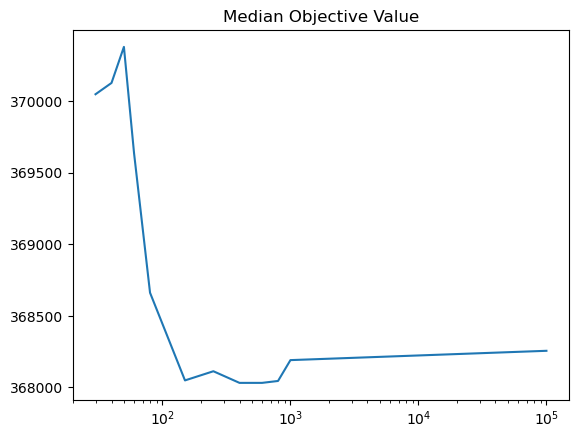

In [6]:
plt.plot(combined_df[(combined_df['scale'] == 100) & 
                         (combined_df['chanceThresh'] == 0.05)].groupby('nTrades')['obj_val'].median())
plt.xscale('log')
plt.title('Median Objective Value')

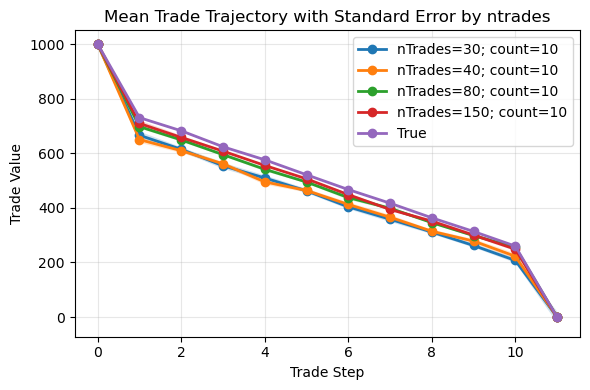

In [7]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['chanceThresh'] == 0.05) &
                         (combined_df['status'] == 2) &
                         (combined_df['scale'] == 100)]
ntrades_groups = df_success.groupby('nTrades')

plt.figure(figsize=(6, 4))

for nTrades, group_data in df_success.groupby('nTrades'):
    if nTrades not in [30, 40, 80, 150, 99999]:
        continue
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    line_label = 'True' if nTrades == 99999 else f'nTrades={nTrades}; count={len(group_data)}'
    plt.plot(x, y, marker='o', label=line_label, linewidth=2)

    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Trade Value')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

<Axes: xlabel='nTrades'>

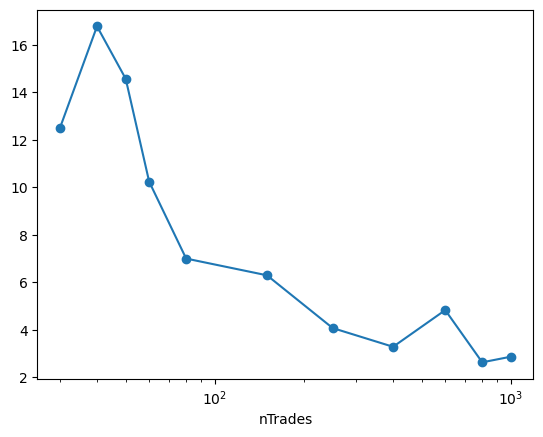

In [8]:
(df_success.groupby('nTrades')[trade_cols].mean() - df_success.groupby('nTrades')[trade_cols].mean().iloc[-1, :]).apply(lambda x: np.abs(x)/12).sum(axis=1).iloc[:-1].plot(logx=True, marker='o')

## uncentred

In [ ]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250930_5e-5']

# Combine data from multiple directories0250921_recenter_posteriors_5e-5
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 12/12 [00:00<00:00, 531.03it/s]


In [10]:
combined_df['failure_rate'] = (1-combined_df['chance_slack']) * combined_df['chanceThresh'] 
combined_df.groupby(['nTrades', 'chanceThresh']).agg({
    'obj_val': ['mean', 'std', lambda x: np.quantile(x, 0.95)], 
    'failure_rate': ['mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val                             failure_rate  \
                               mean          std     <lambda_0>         mean   
nTrades chanceThresh                                                           
50      0.10                    NaN          NaN            NaN          NaN   
60      0.05                    NaN          NaN            NaN          NaN   
80      0.10          385228.395548   792.883880  385630.879905       0.0982   
150     0.10          376515.842035   839.729438  377613.382623       0.0758   
250     0.10          374488.953817   555.242427  375098.976980       0.0670   
400     0.10          370668.610209   550.051755  371183.842046       0.0542   
600     0.10          369865.924262   667.261496  370590.413859       0.0514   
800     0.10          369078.038683   605.359777  369510.284158       0.0504   
1000    0.10          369066.130138   525.687905  369455.509147       0.0498   
99999   0.10          368227.730329  1638.701683  370880.142464       0.0500   

                                     status        
                           std optimal rate count  
nTrades chanceThresh                               
50      0.10               NaN          0.0     5  
60      0.05               NaN          0.0    10  
80      0.10          0.003033          0.8     5  
150     0.10          0.010521          1.0     5  
250     0.10          0.008426          1.0     5  
400     0.10          0.005630          1.0     5  
600     0.10          0.007197          1.0     5  
800     0.10          0.006542          1.0     5  
1000    0.10          0.007259          1.0     5  
99999   0.10          0.007242          1.0    10

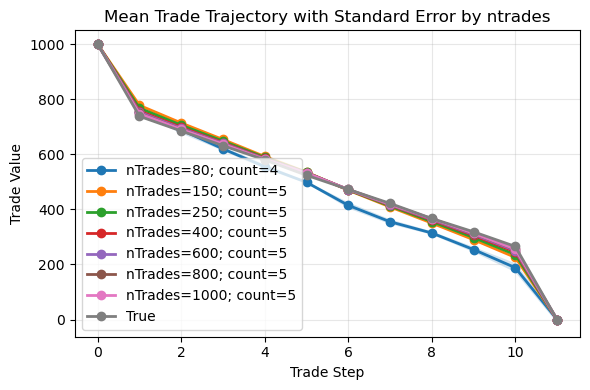

In [11]:
# Group by ntrades and calculate mean and standard error for each trade column
trade_cols = [f'trade_{j}' for j in range(11)]
df_success = combined_df[(combined_df['chanceThresh'] == 0.10) &
                         (combined_df['status'] == 2)]
ntrades_groups = df_success.groupby('nTrades')

plt.figure(figsize=(6, 4))

for nTrades, group_data in df_success.groupby('nTrades'):
    # Calculate mean and standard error for each trade column
    means = [0]
    std_errors = [0]

    for col in trade_cols:
        mean_val = group_data[col].mean()
        std_val = group_data[col].std()
        n_samples = len(group_data)
        std_error = std_val / np.sqrt(n_samples)
        
        means.append(mean_val)
        std_errors.append(std_error)
    
    means = np.array(means)
    std_errors = np.array(std_errors)
    x = np.arange(12)  # Trade steps 0 to 10
    y = np.sum(means) - np.cumsum(means)
    # Plot mean trajectory
    line_label = 'True' if nTrades == 99999 else f'nTrades={nTrades}; count={len(group_data)}'
    plt.plot(x, y, marker='o', label=line_label, linewidth=2)

    # Add standard error bands
    plt.fill_between(x, y - std_errors, y + std_errors, alpha=0.2)

plt.xlabel('Trade Step')
plt.ylabel('Trade Value')
plt.title('Mean Trade Trajectory with Standard Error by ntrades')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Text(0.5, 1.0, 'Normalized Mean-Squared Error against Trades under no Uncentainty')

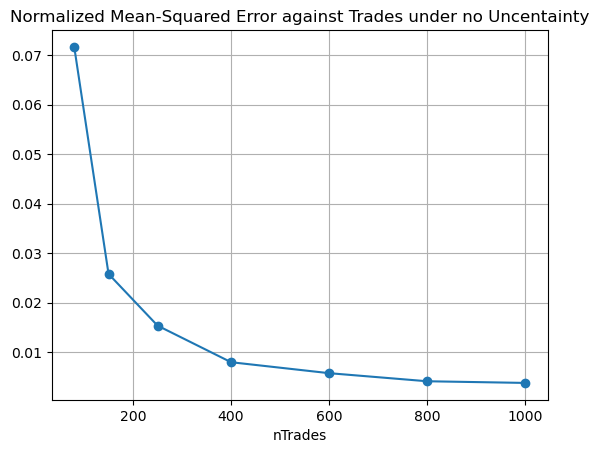

In [17]:
true_trades = df_success[df_success['nTrades'] == 99999][trade_cols].mean()
df_MSE = ((df_success[trade_cols] - true_trades) ** 2).sum(axis=1).groupby(df_success['nTrades']).mean()
norm = (true_trades ** 2).sum()
(df_MSE / norm).iloc[:-1].plot(marker='o')
plt.grid()
plt.title('Normalized Mean-Squared Error against Trades under no Uncentainty')

In [23]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250915_vary_nScenarios']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 3/3 [00:00<00:00, 475.13it/s]


In [24]:
combined_df.groupby(['nTrades', 'nScenarios', 'chanceThresh']).agg({
    'obj_val': ['median', 'mean', 'std'], 
    'chance_slack': ['median', 'mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val                            \
                                        median         mean          std   
nTrades nScenarios chanceThresh                                            
150     300        0.05          754852.122122  754231.1643  2156.118422   
        1000       0.05                    NaN          NaN          NaN   

                                chance_slack                 status        
                                      median mean  std optimal rate count  
nTrades nScenarios chanceThresh                                            
150     300        0.05                  0.0  0.0  0.0         0.15    20  
        1000       0.05                  NaN  NaN  NaN         0.00    20

In [3]:

# Base directory
base_dirs = ['/nfs/home/dannis/AC-model/TIM_opt_results/20250915_vary_nScenarios_add_samples']

# Combine data from multiple directories
all_data = []
for base_dir in base_dirs:
    df = get_mip_info(base_dir)
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

100%|██████████| 2/2 [00:00<00:00, 357.05it/s]


In [4]:
combined_df.groupby(['nTrades', 'nScenarios', 'chanceThresh']).agg({
    'obj_val': ['median', 'mean', 'std'], 
    'chance_slack': ['median', 'mean', 'std'],
    'status': [('optimal rate', lambda x: (x == 2).mean()),
        ('count', 'count')]})

obj_val                            \
                                        median         mean          std   
nTrades nScenarios chanceThresh                                            
150     300        0.05          754852.122122  754231.1643  2156.118422   

                                chance_slack                 status        
                                      median mean  std optimal rate count  
nTrades nScenarios chanceThresh                                            
150     300        0.05                  0.0  0.0  0.0         0.15    20

In [6]:
import pickle
dir = '/nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results/20250916_online_5e-5/nTrades40_posteriors.pkl'
with open(dir, 'rb') as f:
    posteriors = pickle.load(f)
    

In [25]:
np.concatenate([[], np.array([1,2,3])])

array([1., 2., 3.])

In [36]:
l = []
l.extend(np.array([1, 2, 3]))

In [4]:
n_trade = 250
seed = 100
n_scenarios = 10000

n_steps = 10
mcmc_results_dir = "/nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results" 
mcmc_timestamp = "20250825"
trace_file = f'trace_{n_trade}_gap_100_seed_{seed}.nc'
posterior_samples, noise = sample_posteriors(f'{mcmc_results_dir}/{mcmc_timestamp}/{trace_file}', n_scenarios, n_steps)


Processing trace file: /nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results/20250825/trace_250_gap_100_seed_100.nc
Mean of Kappa: 0.0011780074661376218, STD: 0.0004773140651808588
Mean of Gamma: 0.000932927289222641, STD: 0.0004830044267464594
Mean of rho: 7.416195634814161, STD: 1.863873085700884


In [44]:
def IS_tim_particles_num(action, posterior_samples, noise, n_scenarios, n_data, total_qty, tau, eta, sigma, spread):
    IS_exprs = []
    for p in range(n_scenarios):
        kappa = posterior_samples["kappa"][p]
        gamma = posterior_samples["gamma"][p]
        rho = 2.231  # Or posterior_samples["rho"][p]
        permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * np.sum(action**2)
        spread_cost = spread * total_qty
        temporary_impact = eta * np.sum(action**2)
        stochastic_term = 0.0
        for k in range(n_data + 1):
            inventory_expr_k = total_qty - np.sum(action[:k+1])
            stochastic_term += inventory_expr_k * noise[p, k]
        stochastic_term = sigma * math.sqrt(tau) * stochastic_term
     
        
        # Simplified transient impact calculation
        decay_factors = np.exp(-rho * tau * np.arange(n_data + 1))
        transient_impact = kappa * np.sum([
            action[k] * np.sum(action[:k] * decay_factors[k::-1][:k]) 
            for k in range(1, n_data + 1)
        ])
        
        IS_p = permanent_impact + spread_cost + temporary_impact - stochastic_term + transient_impact
        IS_exprs.append(IS_p)
    return np.array(IS_exprs)

In [72]:
total_qty = 1e5
T = 1
n_steps = 10
tau = T / n_steps
spread = 0
q = 5_00
eta = 1 / (q * 2)
sigma = 0.45


0.7366127115939658


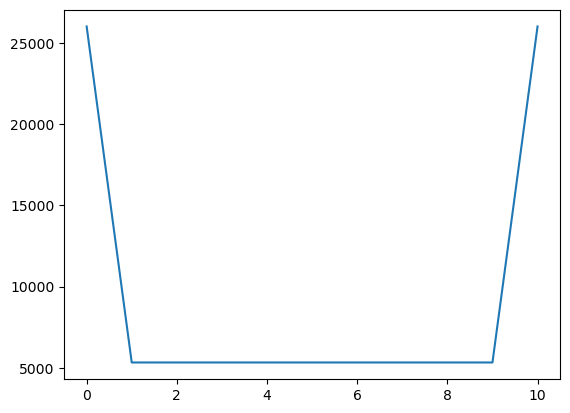

In [76]:
action = np.zeros(n_steps + 1)
action[0] = total_qty
# action = np.ones(n_steps + 1) * (total_qty / (n_steps + 1))
action[0] = 26000
action[-1] = 26000
action[1:-1] = (total_qty - action[0] - action[-1]) / (n_steps - 1)
assert np.isclose(np.sum(action), total_qty)
IS_exprs = IS_tim_particles_num(action, posterior_samples, noise, n_scenarios, n_steps, total_qty, tau, eta, sigma, spread)
plt.plot(action)
print(np.mean(IS_exprs / (eta * (total_qty**2 / T))))

0.7654022219721794


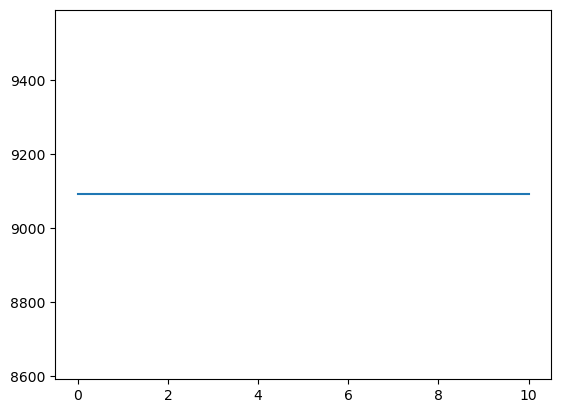

In [77]:

action = np.ones(n_steps + 1) * (total_qty / (n_steps + 1))

assert np.isclose(np.sum(action), total_qty)
IS_exprs = IS_tim_particles_num(action, posterior_samples, noise, n_scenarios, n_steps, total_qty, tau, eta, sigma, spread)
plt.plot(action)
print(np.mean(IS_exprs / (eta * (total_qty**2 / T))))

1.0


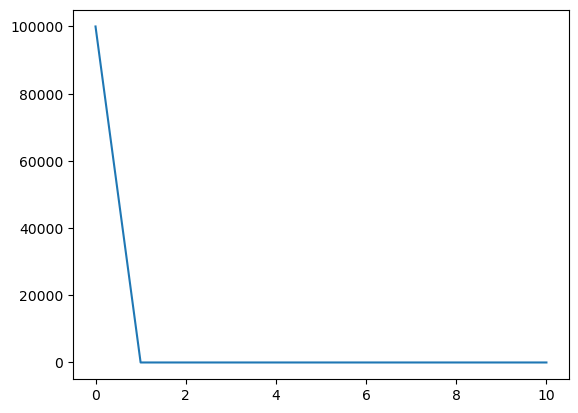

In [67]:
action = np.zeros(n_steps + 1)
action[0] = total_qty
assert np.isclose(np.sum(action), total_qty)
IS_exprs = IS_tim_particles_num(action, posterior_samples, noise, n_scenarios, n_steps, total_qty, tau, eta, sigma, spread)
plt.plot(action)
print(np.mean(IS_exprs / (eta * (total_qty**2 / T))))